# Taller de destilación en pequeño · Colab con GPU

Corre el taller **tal como viene** (dominio por defecto del profesor: IA generativa) con el **profesor real de OpenAI** y la GPU de Colab.
Plan escalonado según los comentarios del profesor (nota del juez después de entrenar > 2/10):

| Corrida | Idioma | Estudiante |
|---|---|---|
| c1_espanol | español (tal cual) | SmolLM2-135M |
| c2_ingles | inglés | SmolLM2-135M |
| c3_ingles_360m | inglés | SmolLM2-360M |

**Antes de empezar**
1. `Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)` → Guardar.
2. Panel izquierdo → 🔑 **Secretos** → `OPENAI_API_KEY` = tu clave (sin comillas) → activa *Acceso del notebook*.
3. Ten a mano `C:\slm\taller-colab.zip`.

Costo: menos de US$ 0,05 por corrida. Con GPU cada corrida tarda pocos minutos.

## 1. Parámetros

In [1]:
# Comenta las corridas que no quieras ejecutar
CORRIDAS = [
    {"nombre": "c1_espanol",     "ingles": False, "estudiante": None},
    {"nombre": "c2_ingles",      "ingles": True,  "estudiante": None},
    {"nombre": "c3_ingles_360m", "ingles": True,  "estudiante": "HuggingFaceTB/SmolLM2-360M-Instruct"},
]

## 2. Verificar la GPU

In [2]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError('No hay GPU: Entorno de ejecución → Cambiar tipo → GPU, y vuelve a conectar.')
print('GPU:', torch.cuda.get_device_name(0), '| VRAM (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

GPU: Tesla T4 | VRAM (GB): 15.6


## 3. Subir y descomprimir el proyecto (taller-colab.zip)

In [3]:
from google.colab import files
from pathlib import Path
import os, shutil, zipfile

up = files.upload()   # selecciona C:\slm\taller-colab.zip
zips = [n for n in up if n.lower().endswith('.zip')]
if len(zips) != 1:
    raise ValueError('Sube exactamente un .zip')
P = Path('/content/taller')
shutil.rmtree(P, ignore_errors=True)
P.mkdir()
with zipfile.ZipFile(zips[0]) as z:
    z.extractall(P)
if (P / '.env').exists():
    raise RuntimeError('El ZIP trae .env: no subas tu clave en el ZIP.')
for f in ['destila.py', 'taller_destilacion.ipynb']:     # copia intacta para restaurar entre corridas
    shutil.copy(P / f, P / (f + '.original'))
(P / 'datos').mkdir(exist_ok=True); (P / 'salidas').mkdir(exist_ok=True)
os.chdir(P)
print(sorted(x.name for x in P.iterdir()))

Saving taller-colab.zip to taller-colab.zip
['.env.example', 'PLANTILLA_INFORME.md', 'README.md', 'aplicar_ingles.py', 'datos', 'destila.py', 'destila.py.original', 'requirements.txt', 'salidas', 'taller_destilacion.ipynb', 'taller_destilacion.ipynb.original']


## 4. Instalar dependencias (sin reinstalar PyTorch: Colab ya lo trae con CUDA)

In [4]:
import subprocess, sys
req = [l.strip() for l in open('requirements.txt', encoding='utf-8')
       if l.strip() and not l.startswith('#') and not l.startswith('--') and not l.lower().startswith('torch')
       and not l.lower().startswith(('jupyter', 'ipykernel'))]
print('Instalando:', req)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *req], check=True)
print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available())

Instalando: ['transformers>=4.56,<5.19', 'peft>=0.17,<0.22', 'accelerate>=1.0', 'safetensors>=0.4', 'tokenizers>=0.21', 'openai>=1.99,<4', 'matplotlib>=3.9', 'pandas>=2.0']
torch 2.11.0+cu130 | CUDA: True


## 5. Clave de OpenAI desde Secretos (no se imprime)

In [5]:
from google.colab import userdata
key = (userdata.get('OPENAI_API_KEY') or '').strip().strip('"').strip("'")
if not key.startswith('sk-'):
    raise RuntimeError('Falta o es inválido el secreto OPENAI_API_KEY (panel 🔑 Secretos).')
os.environ['OPENAI_API_KEY'] = key
del key
print('Clave cargada (oculta).')

Clave cargada (oculta).


## 6. Prueba simulada (buena práctica: sin API ni costo, valida que todo corre)

In [11]:
r = subprocess.run([sys.executable, 'destila.py', '--sin-internet'], capture_output=True, text=True,
                   env={**os.environ, 'OPENAI_API_KEY': '', 'PYTHONUTF8': '1'})
print('\n'.join(l for l in r.stdout.splitlines() if 'RESULTADO' in l or 'Configuración' in l) or r.stdout[-2000:] + r.stderr[-2000:])
for f in ['entrenamiento.jsonl', 'examen.jsonl']:
    (P / 'datos' / f).unlink(missing_ok=True)
for x in (P / 'salidas').iterdir():
    shutil.rmtree(x) if x.is_dir() else x.unlink()

# Aseguramos que el directorio de corridas exista para evitar errores en las celdas finales
(P / 'corridas').mkdir(exist_ok=True)

print('Salidas simuladas eliminadas: NO cuentan como entrega.')

✔ Configuración: profesor = offline (simulado) · estudiante = tiny · dispositivo = cuda
Salidas simuladas eliminadas: NO cuentan como entrega.


## 7. Corridas reales con el profesor de OpenAI (GPU)

In [17]:
import json, statistics, time, subprocess, sys

# Corregimos el conflicto de dependencias instalando una versión compatible de torchao
print("Actualizando torchao para resolver la incompatibilidad con peft...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchao>=0.16.0"], check=True)

def media(ruta):
    notas = [json.loads(l)['nota'] for l in ruta.read_text(encoding='utf-8').splitlines() if l.strip()]
    return round(statistics.mean(notas), 2), round(sum(n >= 7 for n in notas) / len(notas), 2)

resumen = []
for c in CORRIDAS:
    t0 = time.time()
    print('=' * 70, '\n', c['nombre'], '\n' + '=' * 70)
    for f in ['destila.py', 'taller_destilacion.ipynb']:
        shutil.copy(P / (f + '.original'), P / f)
    if c['ingles']:
        subprocess.run([sys.executable, 'aplicar_ingles.py'], check=True)
    for f in ['entrenamiento.jsonl', 'examen.jsonl']:
        (P / 'datos' / f).unlink(missing_ok=True)
    for x in (P / 'salidas').iterdir():
        shutil.rmtree(x) if x.is_dir() else x.unlink()
    cmd = [sys.executable, 'destila.py'] + (['--estudiante', c['estudiante']] if c['estudiante'] else [])
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                            env={**os.environ, 'PYTHONUNBUFFERED': '1', 'PYTHONUTF8': '1'})
    for line in proc.stdout:
        if 'Warning' not in line and 'warnings.warn' not in line:
            print(line, end='')
    proc.wait()
    if proc.returncode != 0:
        print('⚠ La corrida falló; sigo con la siguiente.')
        continue
    dest = P / 'corridas' / c['nombre']
    shutil.rmtree(dest, ignore_errors=True)
    shutil.copytree(P / 'datos', dest / 'datos')
    shutil.copytree(P / 'salidas', dest / 'salidas')
    shutil.copy(P / 'destila.py', dest / 'destila.py')
    a, ap = media(P / 'salidas' / 'examen_antes.jsonl')
    d, dp = media(P / 'salidas' / 'examen_despues.jsonl')
    resumen.append({'corrida': c['nombre'], 'idioma': 'inglés' if c['ingles'] else 'español',
                    'estudiante': c['estudiante'] or 'HuggingFaceTB/SmolLM2-135M-Instruct',
                    'nota_antes': a, 'nota_despues': d, 'aprob_antes': ap, 'aprob_despues': dp,
                    'minutos': round((time.time() - t0) / 60, 1), 'supera_2': d > 2})
    (P / 'corridas' / 'resumen_colab.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding='utf-8')
print('\nListo.')

Actualizando torchao para resolver la incompatibilidad con peft...
 c1_espanol 
✔ Configuración: profesor = openai (gpt-6-luna) · estudiante = HuggingFaceTB/SmolLM2-135M-Instruct · dispositivo = cuda
→ El profesor (gpt-6-luna) escribe 72 preguntas sobre 6 temas…
→ 72 preguntas. El profesor las responde…
✔ 60 pares de entrenamiento · 12 preguntas de examen · 43 s · profesor: 78 llamadas · 8,913 tokens de entrada · 13,784 de salida · ≈ US$ 0.0078
→ Cargando estudiante 'HuggingFaceTB/SmolLM2-135M-Instruct' (la primera vez se descarga desde Hugging Face)…

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1187.56it/s]
✔ Estudiante listo: 135 M parámetros · LoRA entrena 4.88 M (3.6 %)
→ [antes] el estudiante responde 12 preguntas…
→ [antes] el juez califica…
✔ [antes] nota media 1/10 · aprobación 0% · 24.8 s
→ Entrenando: 60 ejemplos · 3 épocas · 45 pasos · lote 4
   época 1 · paso 5/45 · pérdida 2.970 · 2 s
   época 1 · paso 10/45 · pérdida 2.967 · 4 s
   época 1 · paso 15/45 · pérdi

## 8. Resumen y gráficos

,corrida,idioma,estudiante,nota_antes,nota_despues,aprob_antes,aprob_despues,minutos,supera_2
0,c1_espanol,español,HuggingFaceTB/SmolLM2-135M-Instruct,1.00,1.08,0.00,0.0,2.2,False
1,c2_ingles,inglés,HuggingFaceTB/SmolLM2-135M-Instruct,2.08,2.83,0.00,0.0,1.9,True
2,c3_ingles_360m,inglés,HuggingFaceTB/SmolLM2-360M-Instruct,4.08,4.58,0.08,0.0,2.1,True



 c1_espanol


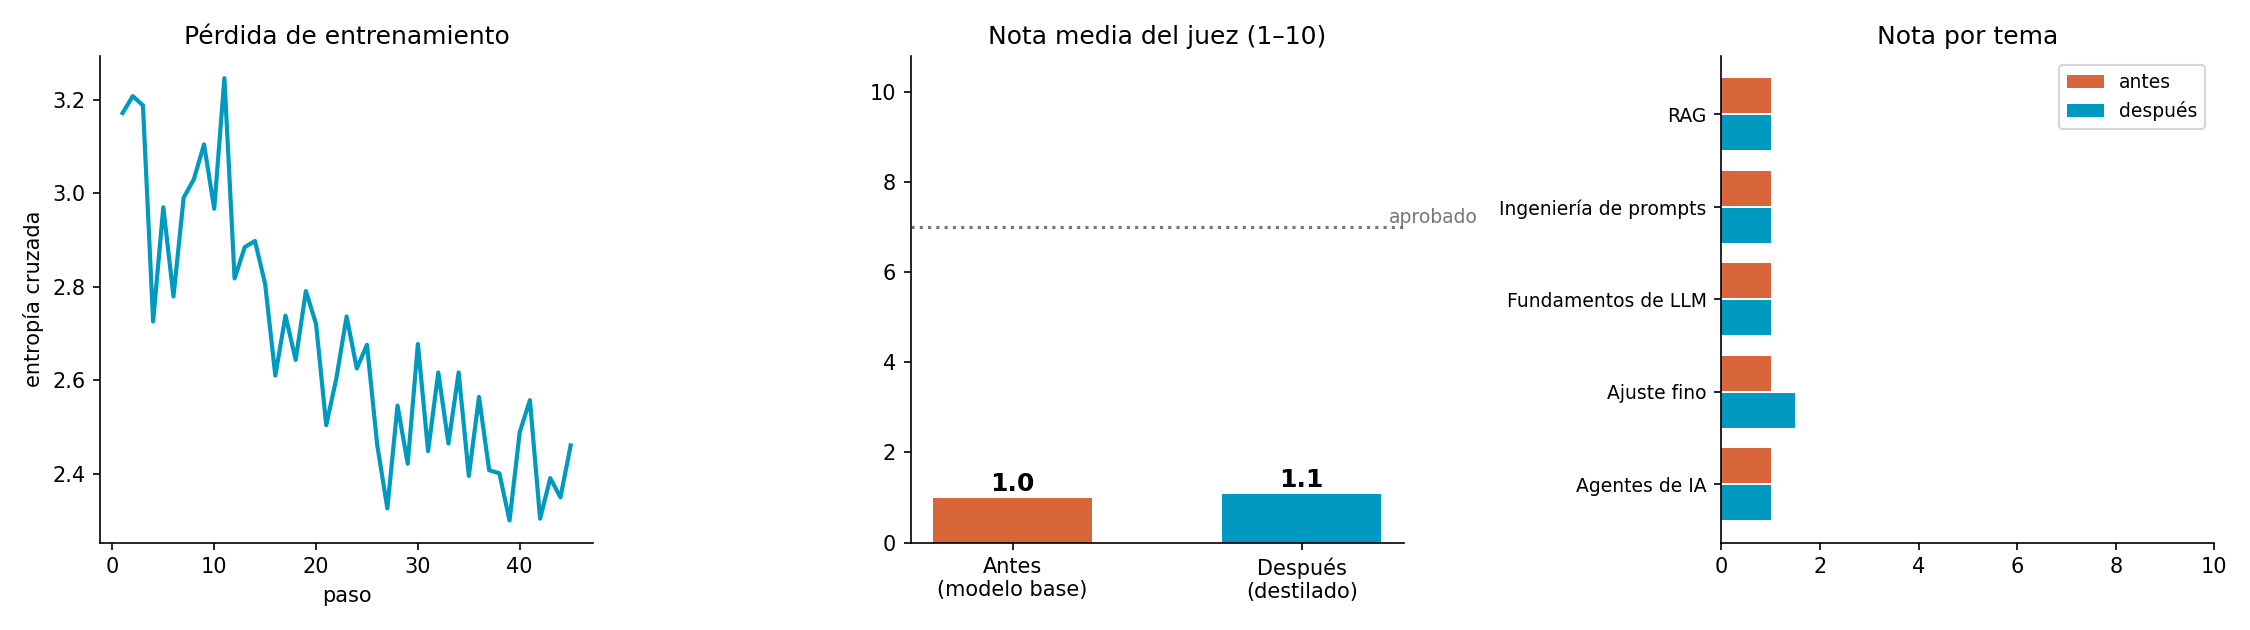


 c2_ingles


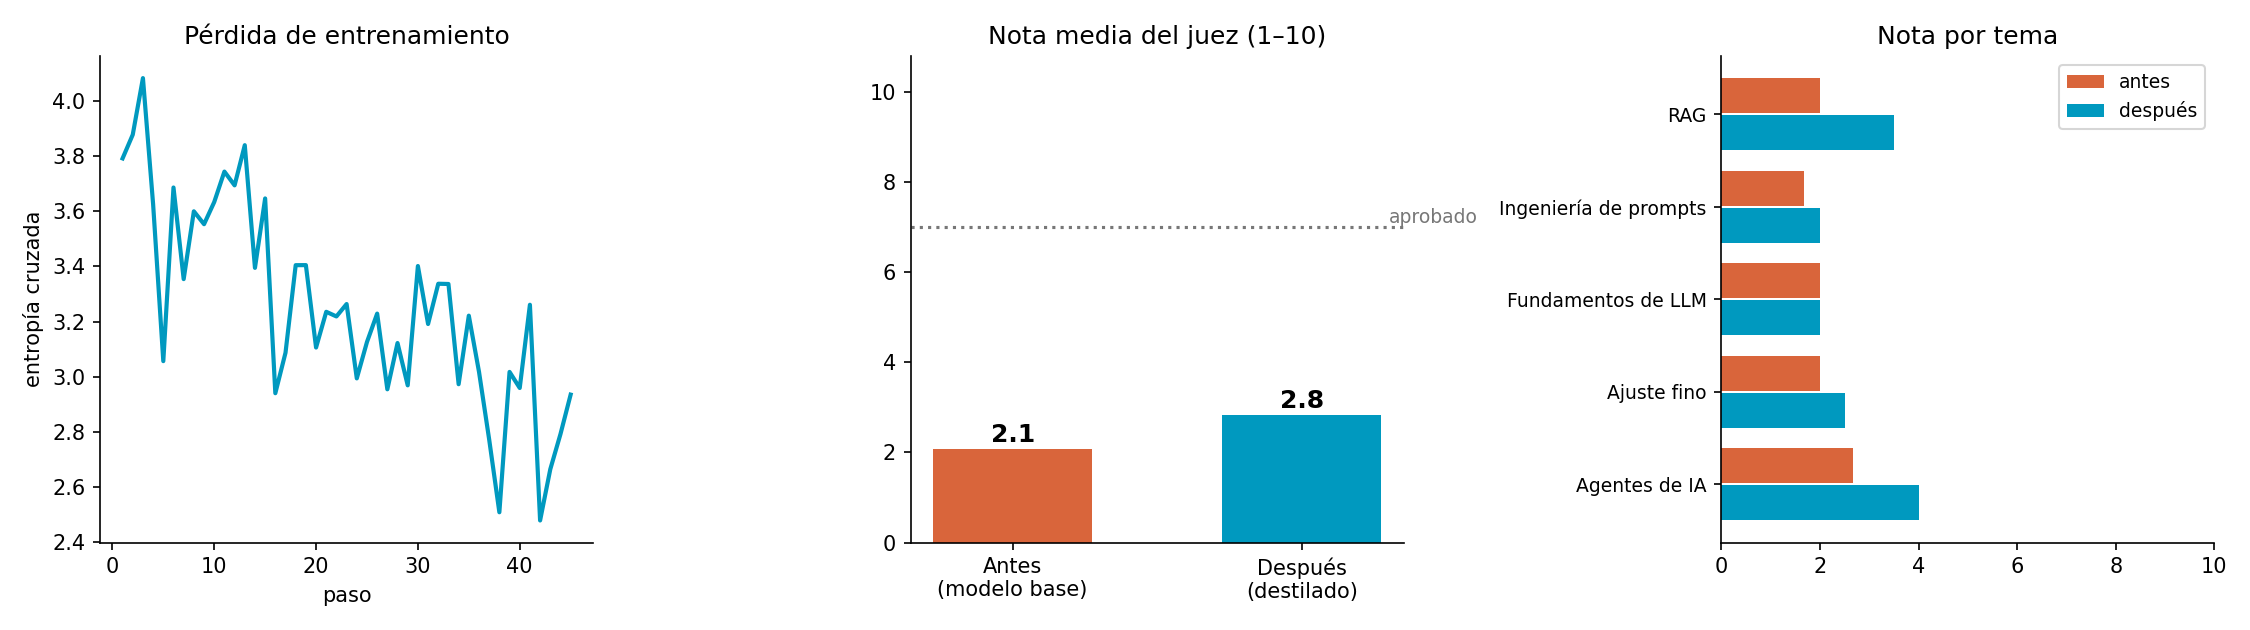


 c3_ingles_360m


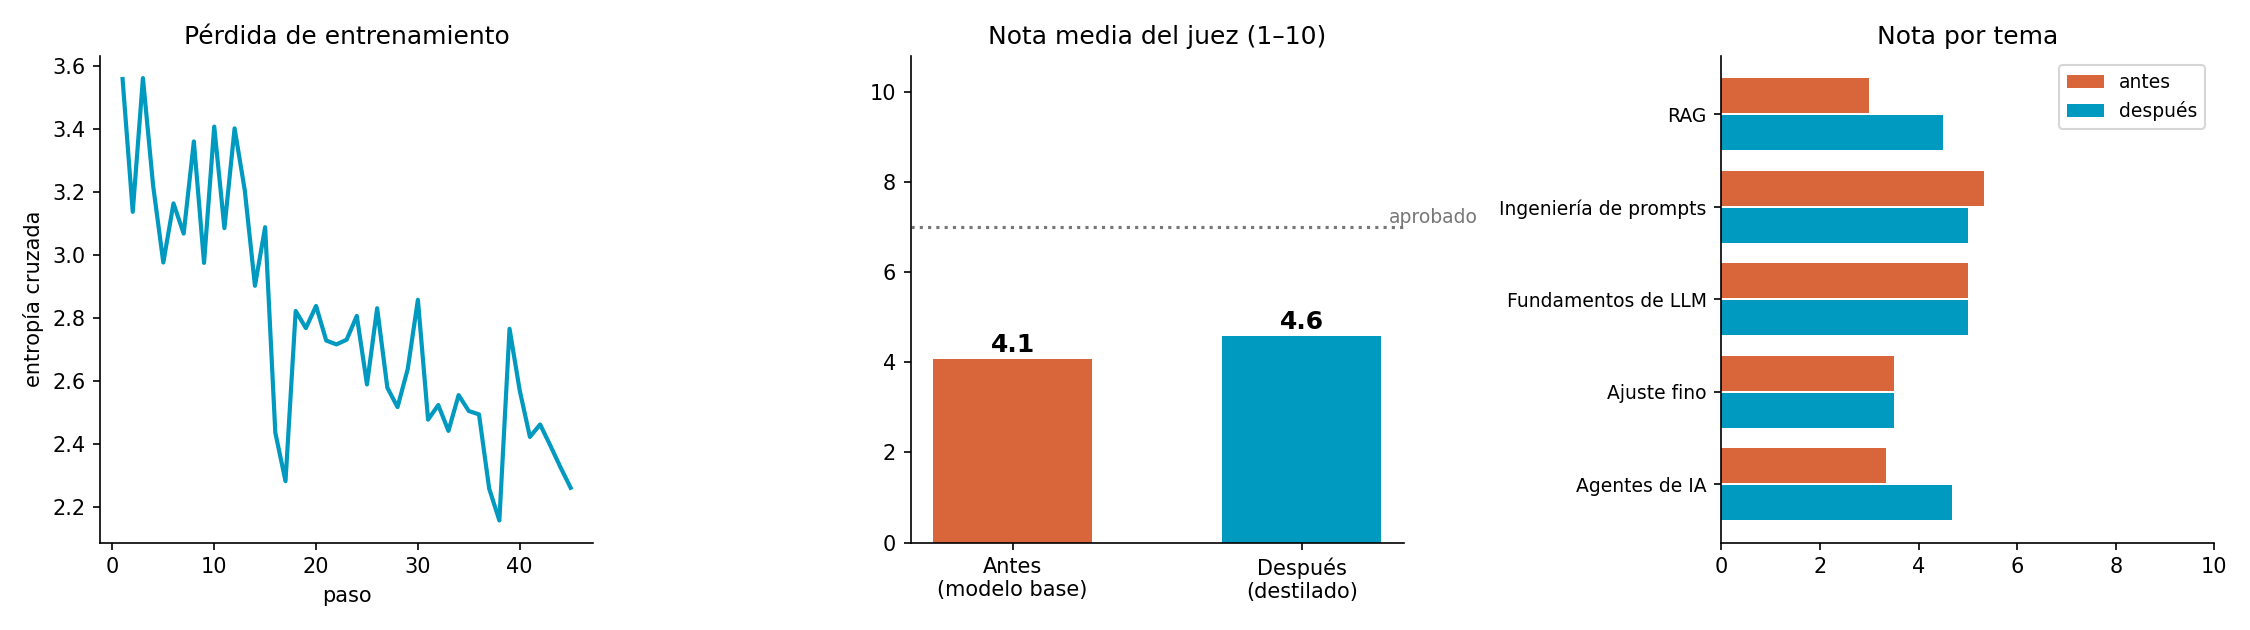

In [18]:
import pandas as pd
from IPython.display import Image, display
display(pd.DataFrame(resumen))
for c in resumen:
    print('\n', c['corrida'])
    display(Image(filename=str(P / 'corridas' / c['corrida'] / 'salidas' / 'resultados.png')))

## 9. Descargar los resultados (corridas_colab.zip)

In [20]:
shutil.make_archive('/content/corridas_colab', 'zip', P / 'corridas')
files.download('/content/corridas_colab.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>